In [1]:
#Ideea: un model doar-linie prezice rezistenta unui izolat doar din „familia“ lui (ST sau cluster HC), fara nicio gena. Il evaluezi sub impartire aleatorie si temporala si masori cat de departe e testul de antrenare.

#incarcare
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, roc_auc_score

df = pd.read_csv("../data/processed/cipro_norvegia.tsv", sep="\t", dtype=str)
df["collection_year"] = df["collection_year"].astype(float).astype(int)
df["y"] = df["y"].astype(int)
print(df.shape, "prevalenta:", round(df["y"].mean(), 3))

(3148, 14) prevalenta: 0.098


In [2]:
#nivelurile de linie (HC0 = foarte fin, HC100 = larg)
NIVELURI = [0, 2, 5, 10, 20, 50, 100]
MODELE = {"ST": "mlst", **{f"HC{h}": f"cgmlst_hc{h}" for h in NIVELURI}}

In [3]:
#cele doua impartiri (cea aleatorie are aceleasi dimensiuni ca cea temporala, ca sa fie comparabile)
def split_temporal(df, an_taiere=2012):
    return df[df["collection_year"] <= an_taiere], df[df["collection_year"] > an_taiere]

def split_aleatoriu(df, n_train, n_test, seed):
    return train_test_split(df, train_size=n_train, test_size=n_test,
                            stratify=df["y"], random_state=seed)

In [4]:
#modelul doar-linie si distanta
def model_linie(train, test, col, alpha=1.0):
    """Probabilitate = proportia de rezistente din antrenare in acelasi cluster/ST.
    Se trage spre prevalenta globala (alpha), iar un cluster nevazut primeste prevalenta."""
    p0 = train["y"].mean()
    stat = train.groupby(col)["y"].agg(["sum", "count"])
    s = test[col].map(stat["sum"]).fillna(0)
    n = test[col].map(stat["count"]).fillna(0)
    return ((s + alpha * p0) / (n + alpha)).values

def distanta_minima(train, test):
    """Cel mai fin nivel HC la care izolatul de test are un 'var' in antrenare (inf = niciunul)."""
    d = pd.Series(np.inf, index=test.index)
    for h in sorted(NIVELURI, reverse=True):      # de la larg la fin, ultimul scris e cel mai fin
        col = f"cgmlst_hc{h}"
        d[test[col].isin(set(train[col]))] = h
    return d

In [5]:
#evaluarea
def evalueaza(train, test):
    """AUROC si castigul AUPRC fata de prevalenta din test (AUPRC al unui model fara informatie)."""
    prev_test = test["y"].mean()
    rez = {}
    for nume, col in MODELE.items():
        scor = model_linie(train, test, col)
        rez[nume] = (roc_auc_score(test["y"], scor),
                     average_precision_score(test["y"], scor) - prev_test)
    return pd.DataFrame(rez, index=["AUROC", "AUPRC_castig"]).T

In [6]:
#impartirea temporala
train_t, test_t = split_temporal(df)
print(len(train_t), len(test_t), "prev train", round(train_t["y"].mean(), 3),
      "prev test", round(test_t["y"].mean(), 3))
rez_t = evalueaza(train_t, test_t)
rez_t.round(3)

1723 1425 prev train 0.066 prev test 0.137


,AUROC,AUPRC_castig
ST,0.877,0.445
HC0,0.500,0.000
HC2,0.500,0.000
HC5,0.502,0.000
HC10,0.526,0.041
HC20,0.665,0.218
HC50,0.857,0.509
HC100,0.897,0.573


In [7]:
#impartirea aleatorie, repetata de 20 de ori, si tabelul comparativ
n_tr, n_te = len(train_t), len(test_t)
rez_a = pd.concat([evalueaza(*split_aleatoriu(df, n_tr, n_te, s)) for s in range(20)])
media_a = rez_a.groupby(level=0).mean().loc[rez_t.index]
std_a = rez_a.groupby(level=0).std().loc[rez_t.index]
tabel = pd.DataFrame({
    "AUROC aleatoriu": media_a["AUROC"].round(3).astype(str) + " +- " + std_a["AUROC"].round(3).astype(str),
    "AUROC temporal": rez_t["AUROC"].round(3),
    "castig AUPRC aleatoriu": media_a["AUPRC_castig"].round(3),
    "castig AUPRC temporal": rez_t["AUPRC_castig"].round(3),
})
tabel

,AUROC aleatoriu,AUROC temporal,castig AUPRC aleatoriu,castig AUPRC temporal
ST,0.893 +- 0.015,0.877,0.459,0.445
HC0,0.503 +- 0.001,0.500,0.000,0.000
HC2,0.523 +- 0.005,0.500,0.022,0.000
HC5,0.547 +- 0.008,0.502,0.043,0.000
HC10,0.62 +- 0.009,0.526,0.146,0.041
HC20,0.765 +- 0.01,0.665,0.357,0.218
HC50,0.895 +- 0.007,0.857,0.577,0.509
HC100,0.913 +- 0.011,0.897,0.623,0.573


In [8]:
#distributia distantelor
ordine = [0, 2, 5, 10, 20, 50, 100, np.inf]
d_t = distanta_minima(train_t, test_t).value_counts(normalize=True).reindex(ordine, fill_value=0)
d_a = pd.concat([distanta_minima(*split_aleatoriu(df, n_tr, n_te, s)).value_counts(normalize=True)
                 .reindex(ordine, fill_value=0) for s in range(20)], axis=1).mean(axis=1)
dist = pd.DataFrame({"aleatoriu": d_a, "temporal": d_t})
dist.index = [f"HC{int(i)}" if np.isfinite(i) else ">HC100" for i in dist.index]
dist.round(3)

,aleatoriu,temporal
HC0,0.005,0.000
HC2,0.020,0.000
HC5,0.035,0.004
HC10,0.070,0.008
HC20,0.160,0.107
HC50,0.306,0.415
HC100,0.202,0.260
>HC100,0.203,0.206


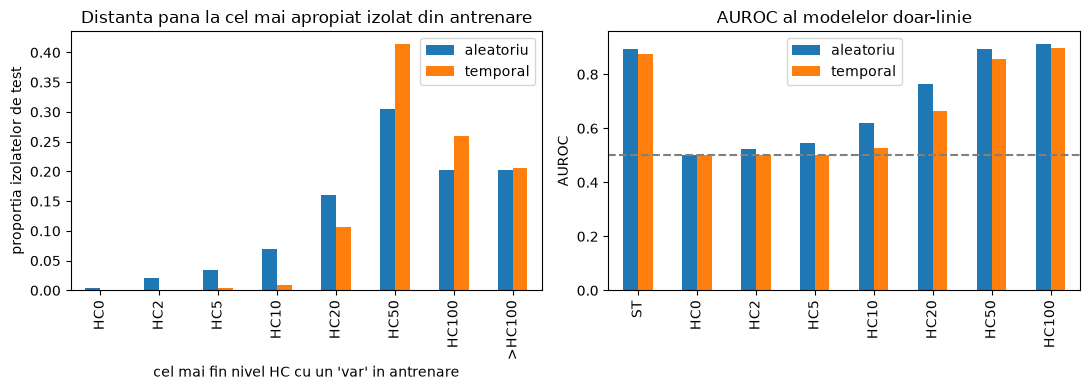

In [9]:
#figura
os.makedirs("../results", exist_ok=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
dist.plot.bar(ax=ax[0])
ax[0].set_title("Distanta pana la cel mai apropiat izolat din antrenare")
ax[0].set_ylabel("proportia izolatelor de test")
ax[0].set_xlabel("cel mai fin nivel HC cu un 'var' in antrenare")
pd.DataFrame({"aleatoriu": media_a["AUROC"], "temporal": rez_t["AUROC"]}).plot.bar(ax=ax[1])
ax[1].set_title("AUROC al modelelor doar-linie")
ax[1].set_ylabel("AUROC")
ax[1].axhline(0.5, color="gray", linestyle="--")
plt.tight_layout()
plt.savefig("../results/poc_linie.png", dpi=150, bbox_inches="tight")

In [10]:
#prevalenta in functie de distanta, la impartirea temporala
d = distanta_minima(train_t, test_t)
test_t.assign(d_min=d.values).groupby("d_min")["y"].agg(["mean", "count"]).round(3)

,mean,count
d_min,,
5.0,0.000,5
10.0,0.750,12
20.0,0.314,153
50.0,0.130,591
100.0,0.078,371
inf,0.109,293


In [11]:
#mai multe puncte de taiere T
rez_T = []
for T in [2008, 2010, 2012, 2014]:
    tr, te = split_temporal(df, T)
    r = evalueaza(tr, te).loc[["ST", "HC20", "HC100"]].copy()
    r["T"], r["n_test"], r["prev_test"] = T, len(te), te["y"].mean()
    rez_T.append(r)
pd.concat(rez_T).round(3)

,AUROC,AUPRC_castig,T,n_test,prev_test
ST,0.852,0.314,2008,2251,0.116
HC20,0.625,0.155,2008,2251,0.116
HC100,0.879,0.484,2008,2251,0.116
ST,0.852,0.341,2010,1865,0.127
HC20,0.619,0.131,2010,1865,0.127
HC100,0.875,0.479,2010,1865,0.127
ST,0.877,0.445,2012,1425,0.137
HC20,0.665,0.218,2012,1425,0.137
HC100,0.897,0.573,2012,1425,0.137
ST,0.886,0.491,2014,924,0.130
